In [1]:
import pandas as pd
import joblib
import shap

from pathlib import Path

In [2]:
model_path = Path("../models/failure_prediction_model.joblib")

model = joblib.load(model_path)

print("Model loaded successfully")

Model loaded successfully


Load the dataset

In [3]:
df = pd.read_csv(
    "../data/raw/manufacturing_data.csv"
)

print(df.shape)

(10000, 16)


Create the feature data

In [4]:
features = [
    "Machine_Type",
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

X = df[features]

Get the trained Random Forest

In [5]:
rf_model = model.named_steps["model"]
preprocessor = model.named_steps["preprocessing"]

Transform the data

In [6]:
X_transformed = preprocessor.transform(X)

In [7]:
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "Features after preprocessing:",
    len(feature_names)
)

Features after preprocessing: 16


Create SHAP TreeExplainer

In [8]:
explainer = shap.TreeExplainer(
    rf_model
)

In [9]:
X_sample = X_transformed[:500]

shap_values = explainer.shap_values(
    X_sample
)

print(type(shap_values)) 

<class 'numpy.ndarray'>


Check SHAP output

In [11]:
print("SHAP shape:", shap_values.shape)
print("Sample shape:", X_sample.shape)
print("Number of transformed features:", len(feature_names))
print("First 10 feature names:")
print(feature_names[:10])

SHAP shape: (500, 16, 2)
Sample shape: (500, 16)
Number of transformed features: 16
First 10 feature names:
['categorical__Machine_Type_CNC' 'categorical__Machine_Type_Grinding'
 'categorical__Machine_Type_Lathe' 'categorical__Machine_Type_Milling'
 'categorical__Machine_Type_Press' 'numerical__Machine_Age_Years'
 'numerical__Operating_Hours' 'numerical__Temperature_C'
 'numerical__Vibration_mm_s' 'numerical__Pressure_bar']


Visualize global SHAP importance

In [1]:
import matplotlib.pyplot as plt
print("Matplotlib working")

Matplotlib working


In [2]:
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

from pathlib import Path

print("Imports successful")

Imports successful


Load the saved model

In [3]:
model_path = Path("../models/failure_prediction_model.joblib")

model = joblib.load(model_path)

print("Model loaded successfully")

Model loaded successfully


Load the dataset

In [4]:
df = pd.read_csv("../data/raw/manufacturing_data.csv")

print(df.shape)

(10000, 16)


Define the exact model features

In [5]:
features = [
    "Machine_Type",
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

X = df[features]

print(X.shape)

(10000, 12)


get the pipeline components

In [6]:
rf_model = model.named_steps["model"]
preprocessor = model.named_steps["preprocessing"]

print("Random Forest and preprocessor loaded")

Random Forest and preprocessor loaded


preprocessing

In [7]:
X_transformed = preprocessor.transform(X)

feature_names = preprocessor.get_feature_names_out()

print("Transformed shape:", X_transformed.shape)
print("Number of feature names:", len(feature_names))

Transformed shape: (10000, 16)
Number of feature names: 16


SHAP

In [8]:
explainer = shap.TreeExplainer(rf_model)

X_sample = X_transformed[:500]

shap_values = explainer.shap_values(X_sample)

print("SHAP type:", type(shap_values))
print("SHAP shape:", shap_values.shape)

SHAP type: <class 'numpy.ndarray'>
SHAP shape: (500, 16, 2)


Extract the failure-class SHAP values

In [9]:
failure_shap_values = shap_values[:, :, 1]

print("Failure SHAP shape:", failure_shap_values.shape)

Failure SHAP shape: (500, 16)


Create global SHAP importance

In [10]:
import numpy as np

mean_abs_shap = np.abs(
    failure_shap_values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance.head(10)

,feature,mean_abs_shap
0,numerical__Operating_Hours,0.083867
1,numerical__Last_Maintenance_Days,0.081891
2,numerical__Machine_Age_Years,0.043983
3,numerical__Temperature_C,0.039869
4,numerical__Vibration_mm_s,0.035675
5,numerical__Failure_Count,0.015659
6,numerical__Pressure_bar,0.013064
7,numerical__Production_Rate,0.008124
8,numerical__Production_Count,0.007496
9,numerical__Motor_Current_A,0.006999


Visualize it

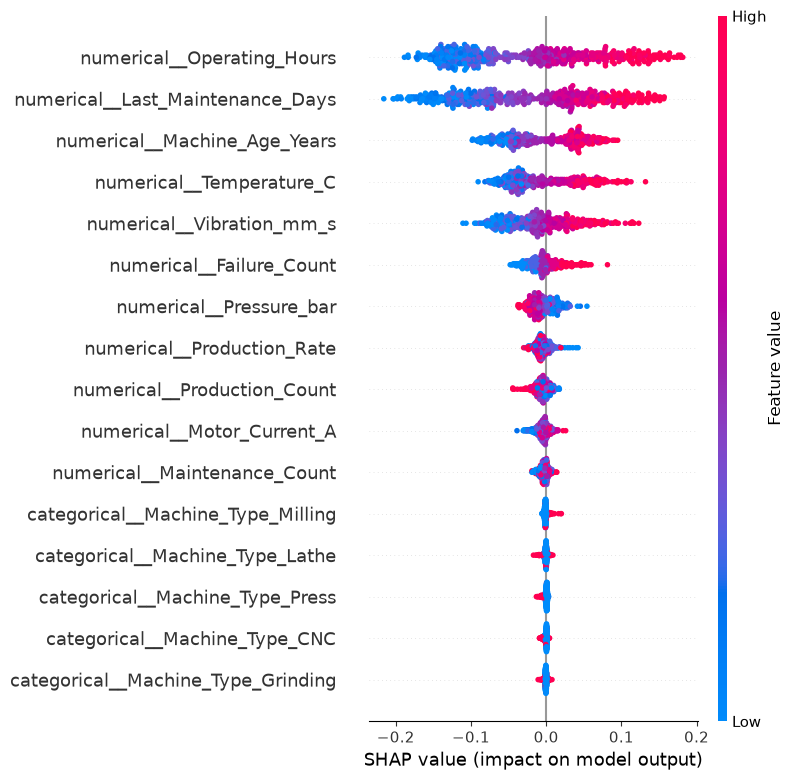

In [11]:
shap.summary_plot(
    failure_shap_values,
    X_sample,
    feature_names=feature_names
)

In [12]:
high_risk_machine = pd.DataFrame([{
    "Machine_Type": "CNC",
    "Machine_Age_Years": 10,
    "Operating_Hours": 30000,
    "Temperature_C": 75,
    "Vibration_mm_s": 5.5,
    "Pressure_bar": 6.0,
    "Motor_Current_A": 20,
    "Production_Count": 1000,
    "Production_Rate": 85,
    "Last_Maintenance_Days": 250,
    "Maintenance_Count": 8,
    "Failure_Count": 3
}])

In [13]:
high_risk_transformed = preprocessor.transform(
    high_risk_machine
)

In [14]:
high_risk_shap_all = explainer.shap_values(
    high_risk_transformed
)

print(
    "Shape:",
    high_risk_shap_all.shape
)

Shape: (1, 16, 2)


In [15]:
high_risk_shap = high_risk_shap_all[0, :, 1]

print(high_risk_shap)

[-0.00766519  0.00071891  0.00019932 -0.00212463  0.00124353  0.051397
  0.0342286   0.03901657  0.05197966 -0.01092093 -0.00266     0.00097269
 -0.00183613  0.05589554 -0.00287746  0.01123981]


In [16]:
contributions = pd.DataFrame({
    "feature": feature_names,
    "shap_value": high_risk_shap
})

contributions["abs_shap"] = (
    contributions["shap_value"].abs()
)

contributions = (
    contributions
    .sort_values(
        "abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

contributions.head(10)

,feature,shap_value,abs_shap
0,numerical__Last_Maintenance_Days,0.055896,0.055896
1,numerical__Vibration_mm_s,0.051980,0.051980
2,numerical__Machine_Age_Years,0.051397,0.051397
3,numerical__Temperature_C,0.039017,0.039017
4,numerical__Operating_Hours,0.034229,0.034229
5,numerical__Failure_Count,0.011240,0.011240
6,numerical__Pressure_bar,-0.010921,0.010921
7,categorical__Machine_Type_CNC,-0.007665,0.007665
8,numerical__Maintenance_Count,-0.002877,0.002877
9,numerical__Motor_Current_A,-0.002660,0.002660
